# Humanoid Robot Task Failure Risk — End-to-End Project

**Course:** CDS4003 Data Science for Business Applications  
**Technical objective:** estimate the probability that a warehouse humanoid robot task will fail, using information available before task execution.

This notebook implements data understanding, deterministic cleaning, EDA, feature engineering, model tuning, threshold analysis, and final holdout evaluation. The dataset is synthetic and user-provided; it is not real Agility Robotics operational data.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import numpy as np
from IPython.display import display, Image

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import DATA_PATH, TABLE_DIR, FIGURE_DIR
from src.data_processing import audit_data, clean_dataset, prepare_model_data, add_engineered_features
from src.reporting import generate_eda, generate_evaluation_figures
from src.modeling import train_final_model
pd.set_option("display.max_columns", 60)
print("Project root resolved from the current working directory.")

Project root resolved from the current working directory.


## 1–2. Business framing and data collection

The prediction target is `task_failure` (1 = failure, 0 = no failure). The intended decision is whether a supervisor should review or adjust a task before execution. The dataset meets the project size requirements: at least 200,000 raw task records and at least 20 columns. Its synthetic nature, missing source licence, and requirement for instructor approval must be disclosed in the student's own report.

In [2]:
raw = pd.read_csv(DATA_PATH, low_memory=False)
print("Raw shape:", raw.shape)
print("Fully blank rows:", raw.isna().all(axis=1).sum())
print("Missing cells:", int(raw.isna().sum().sum()))
print("Duplicate task IDs:", int(raw["task_id"].dropna().duplicated().sum()))
display(audit_data(raw, "raw"))

Raw shape: (200200, 30)
Fully blank rows: 200
Missing cells: 113967
Duplicate task IDs: 0


,stage,column,dtype,missing_n,missing_pct,unique_n
0,raw,task_id,float64,200,0.100,200000
1,raw,shift,object,4136,2.066,6
2,raw,warehouse_zone,object,4161,2.078,8
3,raw,task_type,object,4094,2.045,8
4,raw,object_weight_kg,float64,4259,2.127,1890
5,raw,object_size_liters,float64,4204,2.100,3899
6,raw,travel_distance_m,float64,4218,2.107,3510
7,raw,obstacles_count,float64,4142,2.069,10
8,raw,human_nearby,object,4210,2.103,6
9,raw,aisle_width_m,float64,4178,2.087,221


## 3. Data understanding and cleaning

Cleaning removes blank rows and exact/ID duplicates, standardizes categorical labels, maps mixed binary values, and converts domain-impossible numbers to missing. Unknown target labels are removed only when creating the modeling matrix. Imputation and scaling are fitted inside each training pipeline to prevent data leakage. Valid extreme values are retained rather than removed solely because they are statistical outliers.

In [3]:
clean, cleaning_summary = clean_dataset(raw)
print(json.dumps({k:v for k,v in cleaning_summary.items() if k != "invalid_by_column"}, indent=2))
display(pd.DataFrame(cleaning_summary["invalid_by_column"]))
audit_data(clean, "after_deterministic_cleaning").to_csv(TABLE_DIR / "notebook_clean_data_audit.csv", index=False)
display(clean.head())

{
  "rows_raw": 200200,
  "blank_rows_removed": 200,
  "duplicate_rows_removed": 0,
  "duplicate_task_ids_removed": 0,
  "domain_invalid_values_set_missing": 1467,
  "rows_after_structural_cleaning": 200000,
  "columns": 30,
  "missing_cells_raw": 113967,
  "missing_cells_after_domain_validation": 109630
}


,column,invalid_n,valid_min,valid_max
0,vision_confidence,294,0.0,1.0
1,battery_level_pct,294,0.0,100.0
2,completion_time_sec,293,0.0,3600.0
3,temperature_c,293,-20.0,60.0
4,object_weight_kg,293,0.0,50.0
5,object_size_liters,0,0.0,100.0
6,floor_friction,0,0.0,1.0
7,aisle_width_m,0,0.3,10.0
8,obstacles_count,0,0.0,20.0
9,travel_distance_m,0,0.0,100.0


,task_id,shift,warehouse_zone,task_type,object_weight_kg,object_size_liters,travel_distance_m,obstacles_count,human_nearby,aisle_width_m,floor_friction,lighting_lux,temperature_c,humidity_pct,battery_level_pct,motor_temperature_c,joint_load_pct,grasp_difficulty_1_to_5,vision_confidence,localization_error_cm,network_latency_ms,previous_task_failures,maintenance_hours_since_service,payload_balance_offset_cm,path_planning_complexity_1_to_10,operator_intervention,completion_time_sec,failure_probability_simulated,task_failure,task_success
0,1.0,afternoon,storage,transport,4.72,11.40,2.60,1.0,0.0,1.43,0.823,255.6,25.9,37.9,83.4,37.6,26.0,2.0,0.893,2.29,95.7,0.0,73.6,2.50,1.0,0.0,35.38,0.16200,1.0,0.0
1,2.0,afternoon,storage,tote_sorting,0.49,8.34,2.26,0.0,0.0,1.56,0.410,305.3,20.7,47.1,81.9,33.5,39.9,3.0,0.989,1.73,58.7,0.0,59.1,3.74,1.0,0.0,24.93,0.35154,0.0,1.0
2,3.0,night,shipping,transport,5.76,8.02,1.26,2.0,1.0,1.19,0.671,161.5,26.4,53.8,60.7,42.2,34.3,2.0,0.978,5.25,33.9,0.0,34.8,0.01,3.0,0.0,31.92,0.50074,0.0,1.0
3,4.0,afternoon,packing,shelf_retrieval,4.47,5.74,1.39,2.0,0.0,2.26,0.723,290.5,27.3,67.6,66.4,33.6,47.0,1.0,0.850,4.07,31.6,0.0,54.4,3.25,2.0,0.0,20.59,0.44033,1.0,0.0
4,5.0,morning,packing,transport,4.86,16.66,8.92,0.0,1.0,1.57,0.817,206.4,NaN,42.8,65.4,45.8,31.1,2.0,1.000,3.75,46.0,0.0,76.4,2.13,2.0,0.0,39.78,0.47935,0.0,1.0


## 4. Exploratory data analysis and feature engineering

The EDA examines missingness, class balance, failure rates by operational categories, numeric distributions, battery/maintenance bands, and correlations. Correlation is associative and does not establish causation.

Seven pre-task features are engineered: load–distance, thermal load, obstacles per 10 m, battery deficit, maintenance–failure interaction, low-battery flag, and low-vision flag. Their value is examined later with permutation importance.

{'labeled_rows': 199950, 'failure_rate': 0.5238959739934984, 'figures': 6}


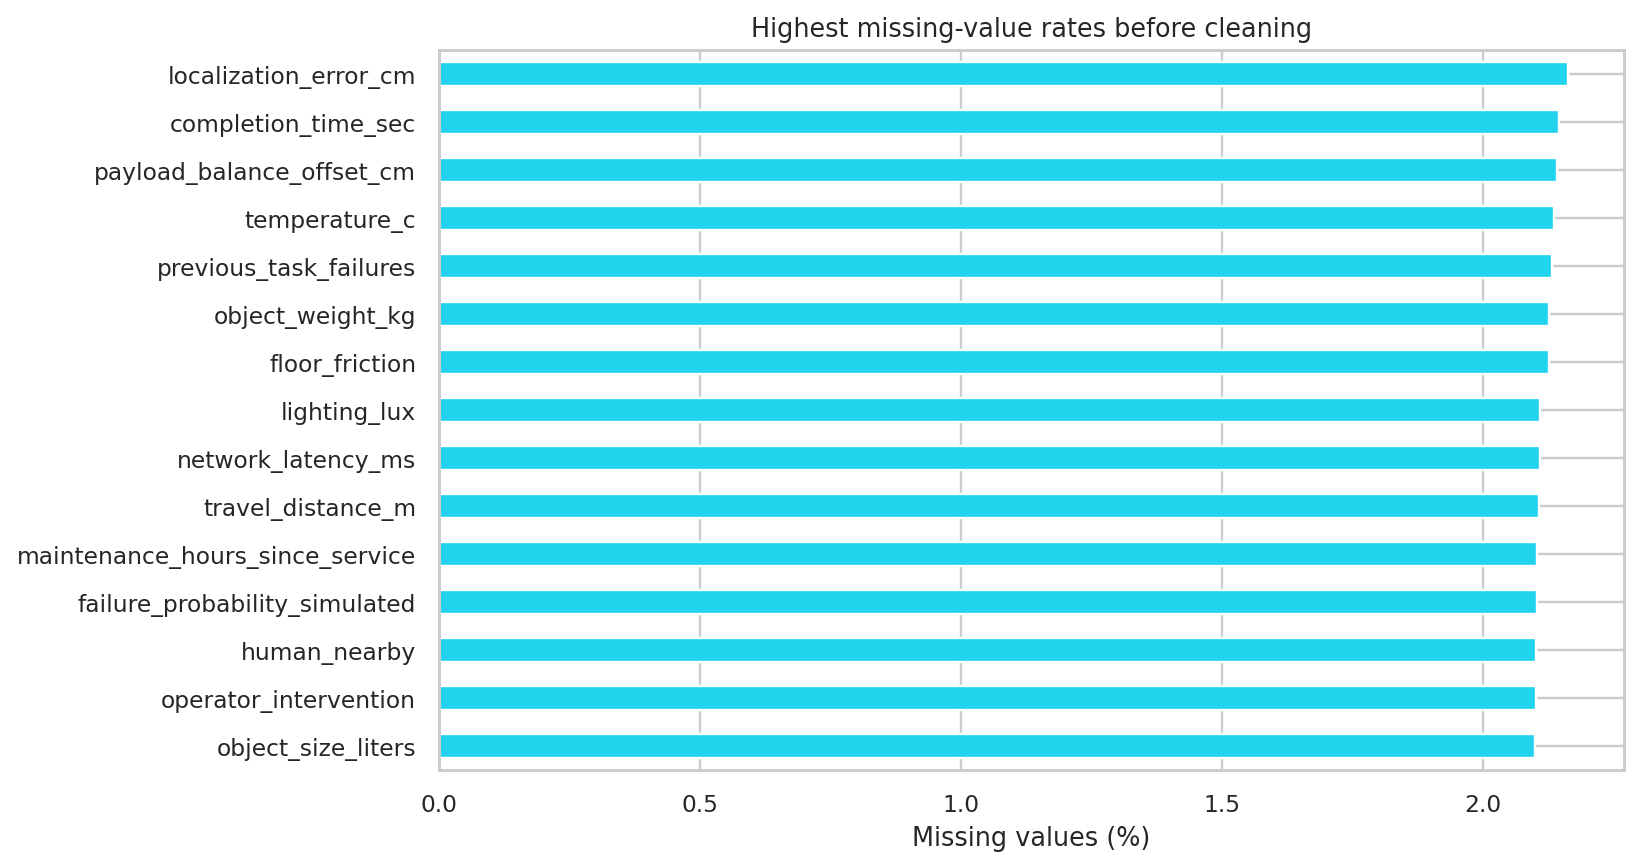

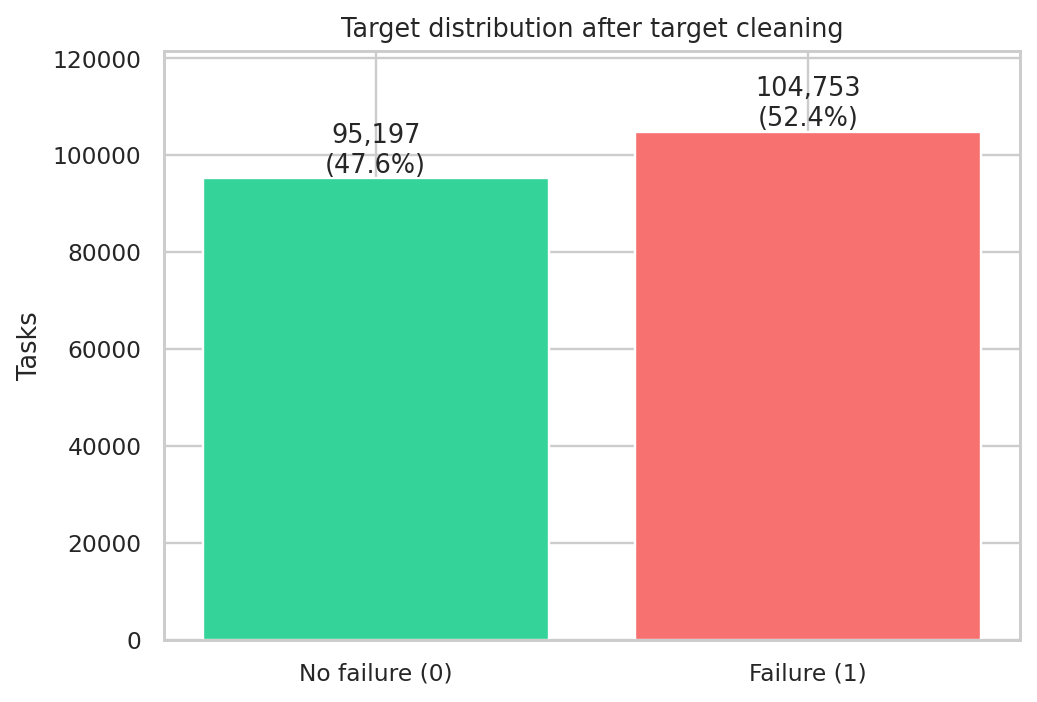

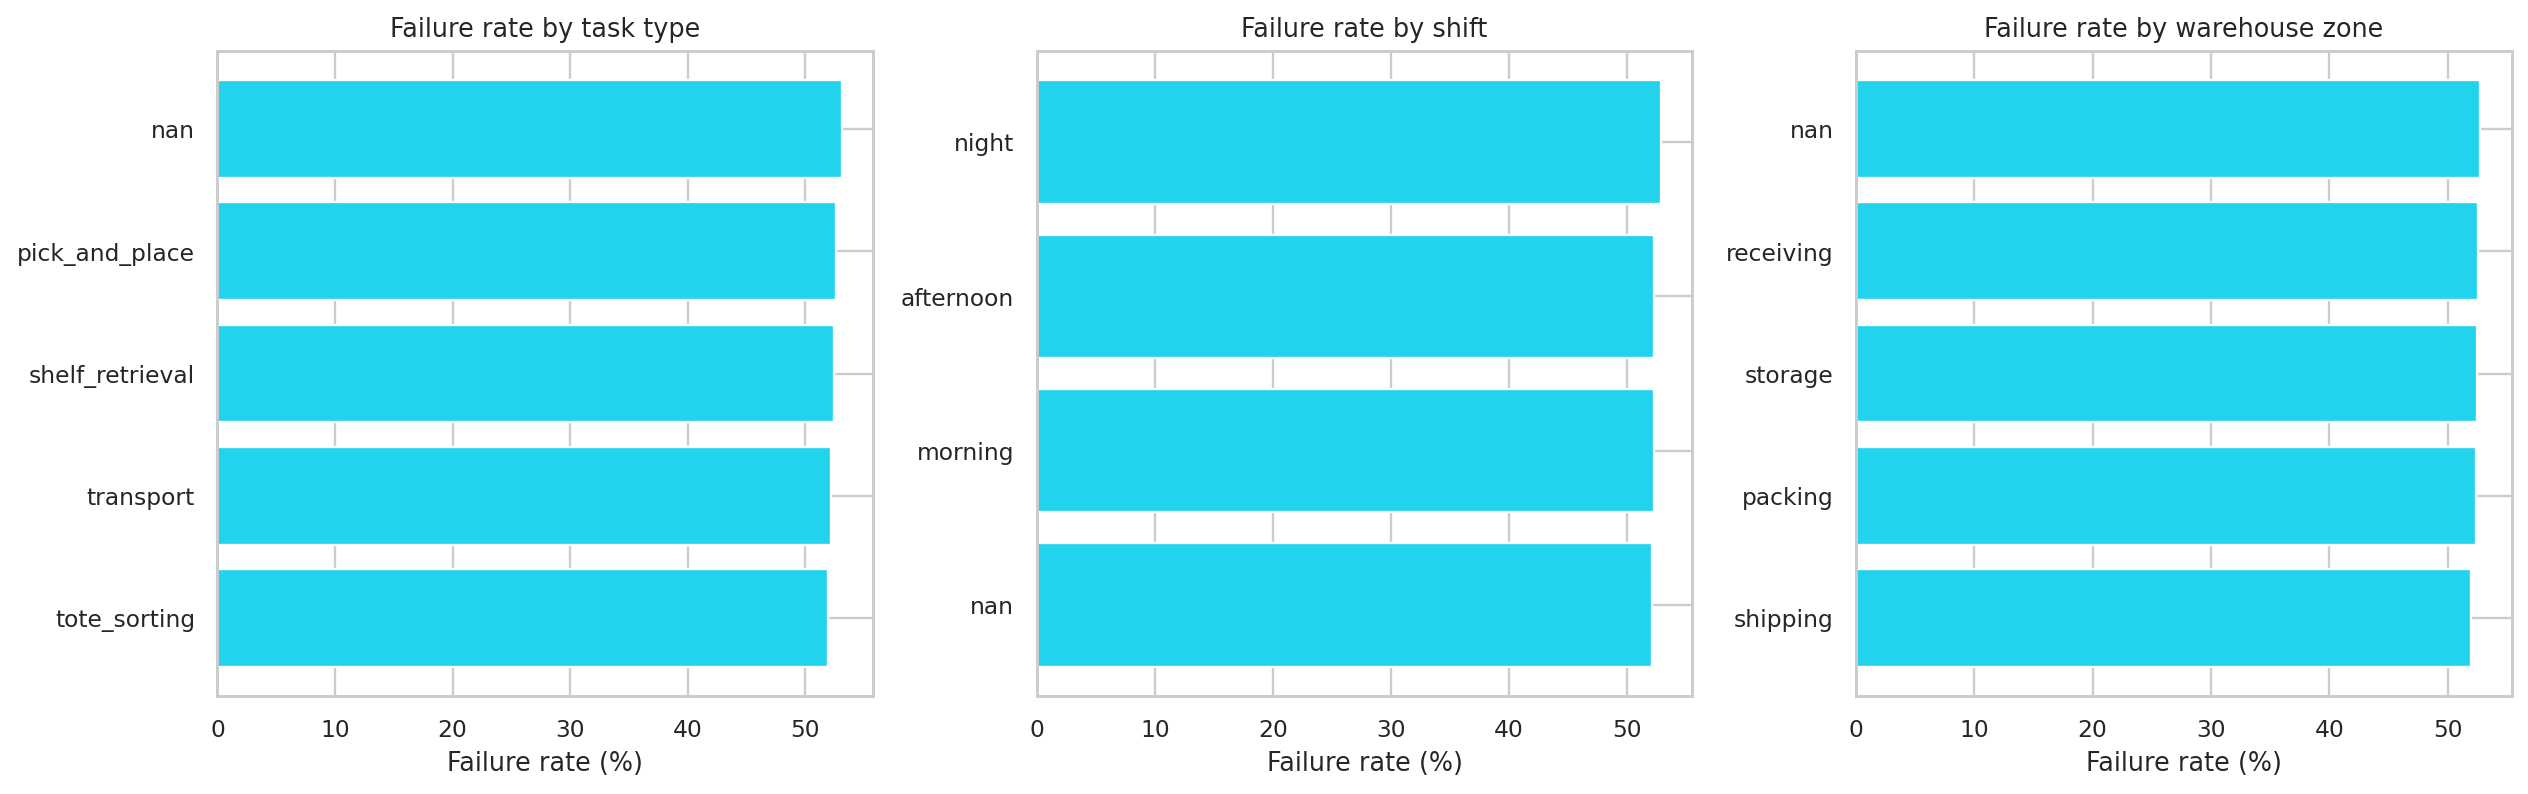

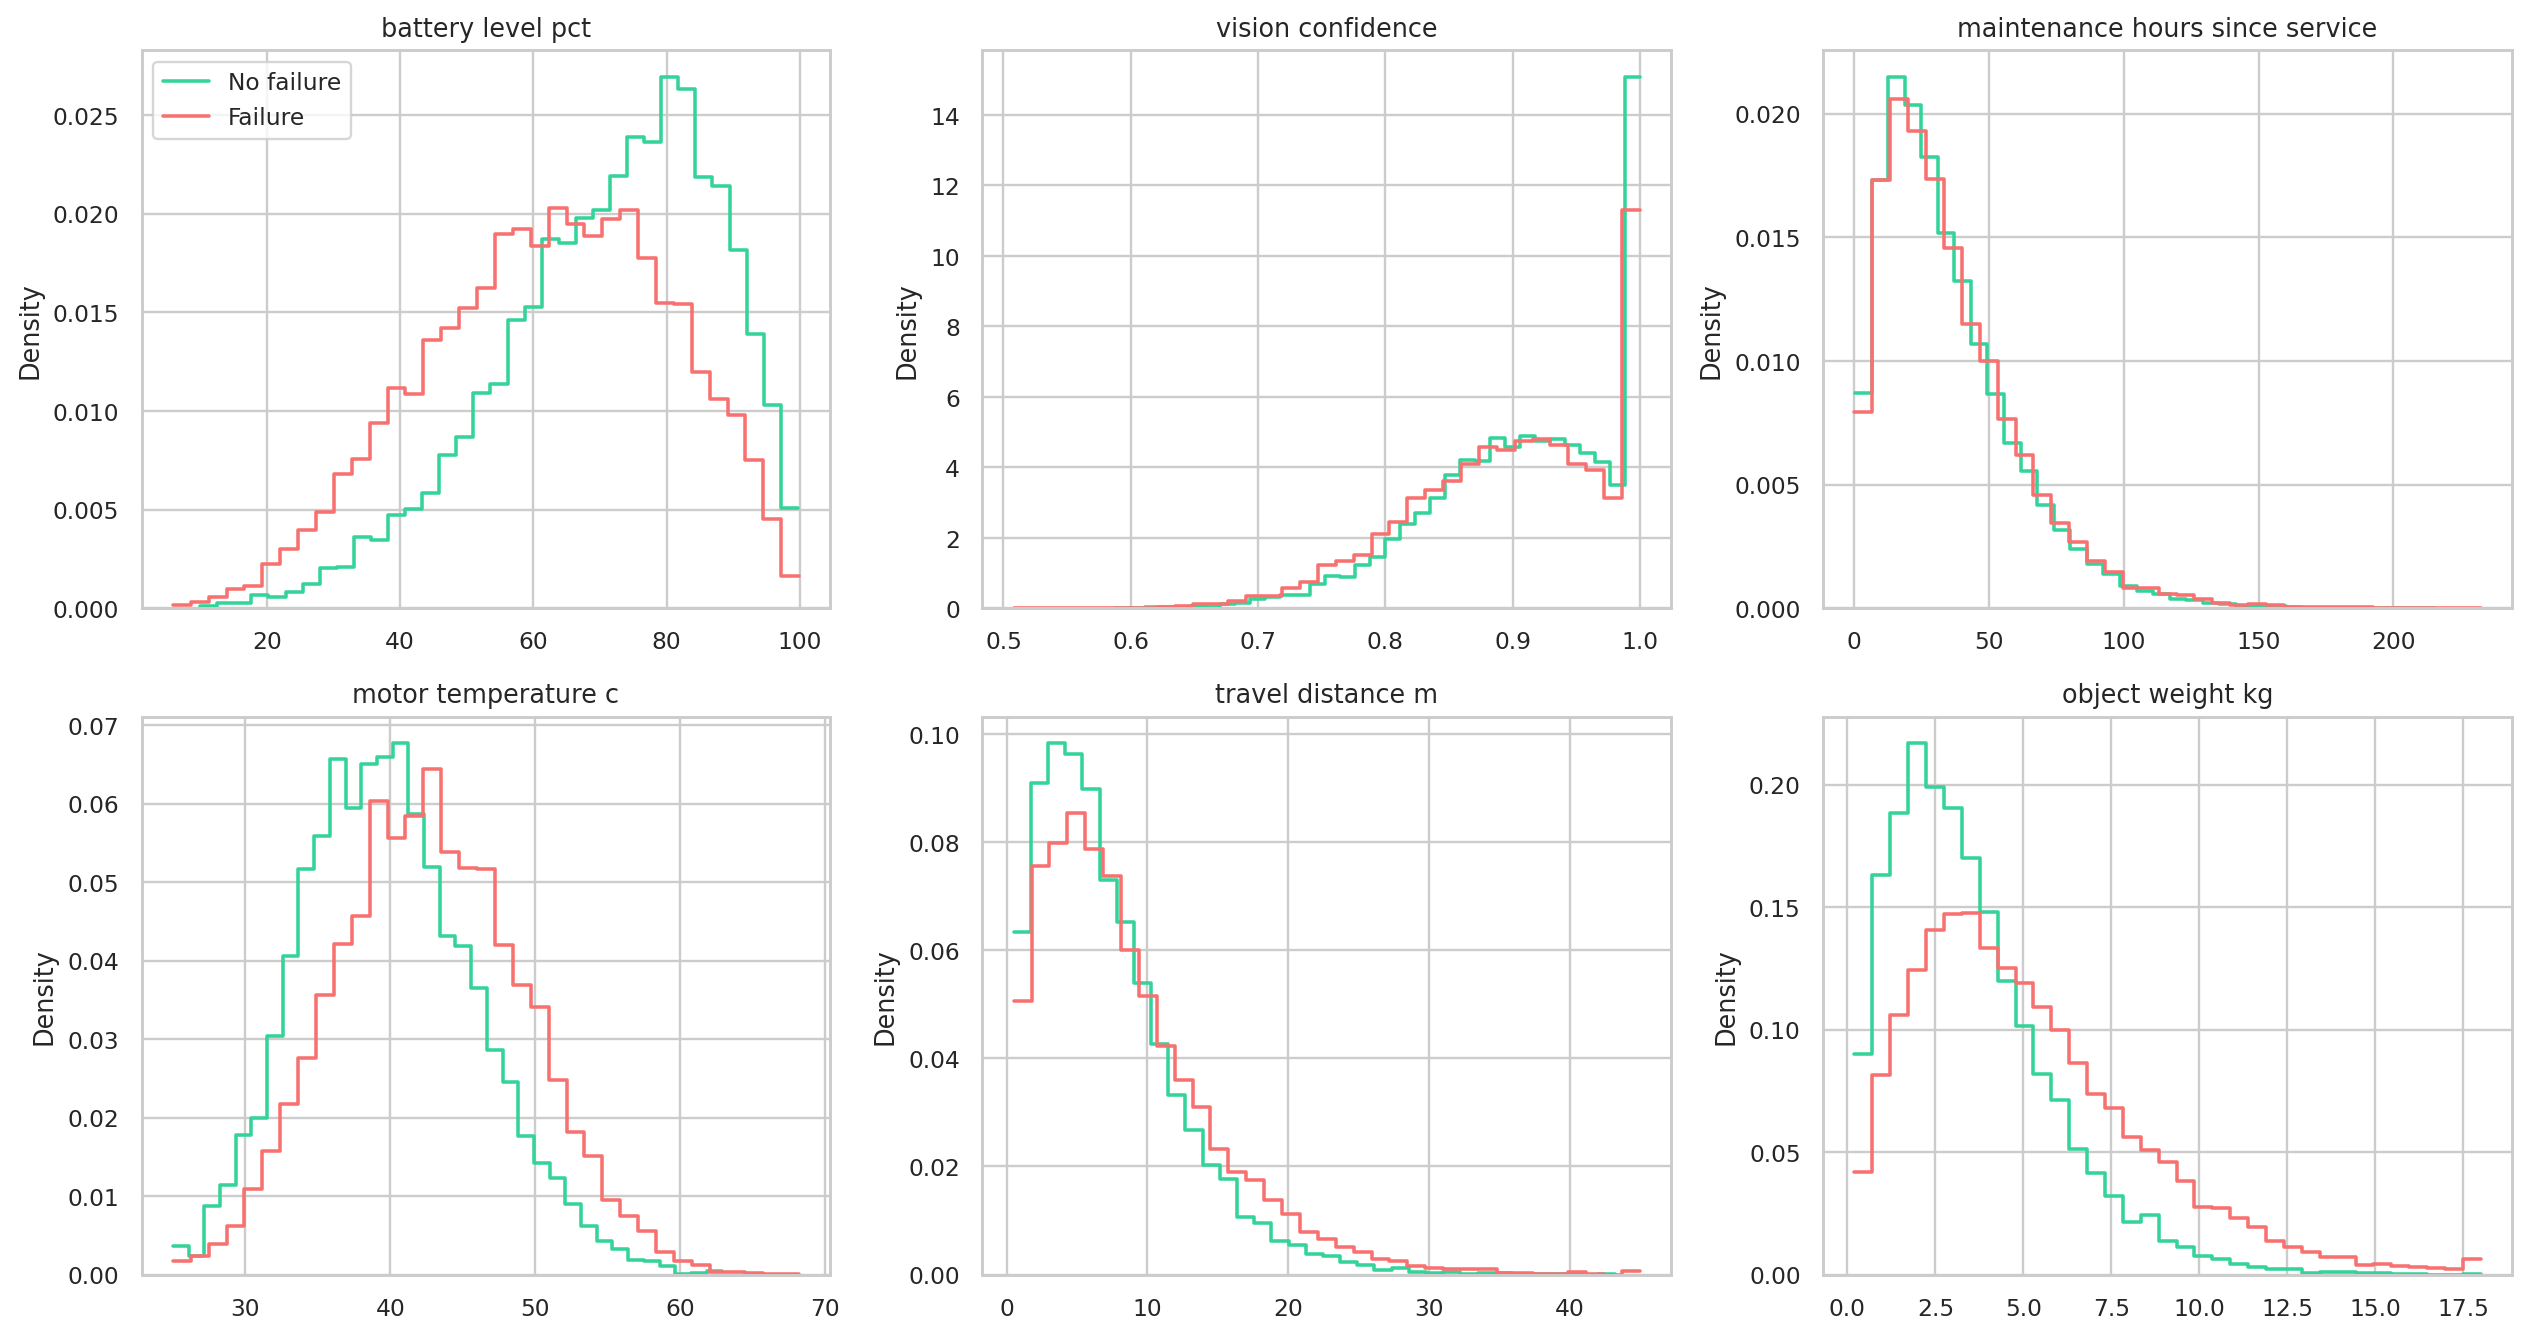

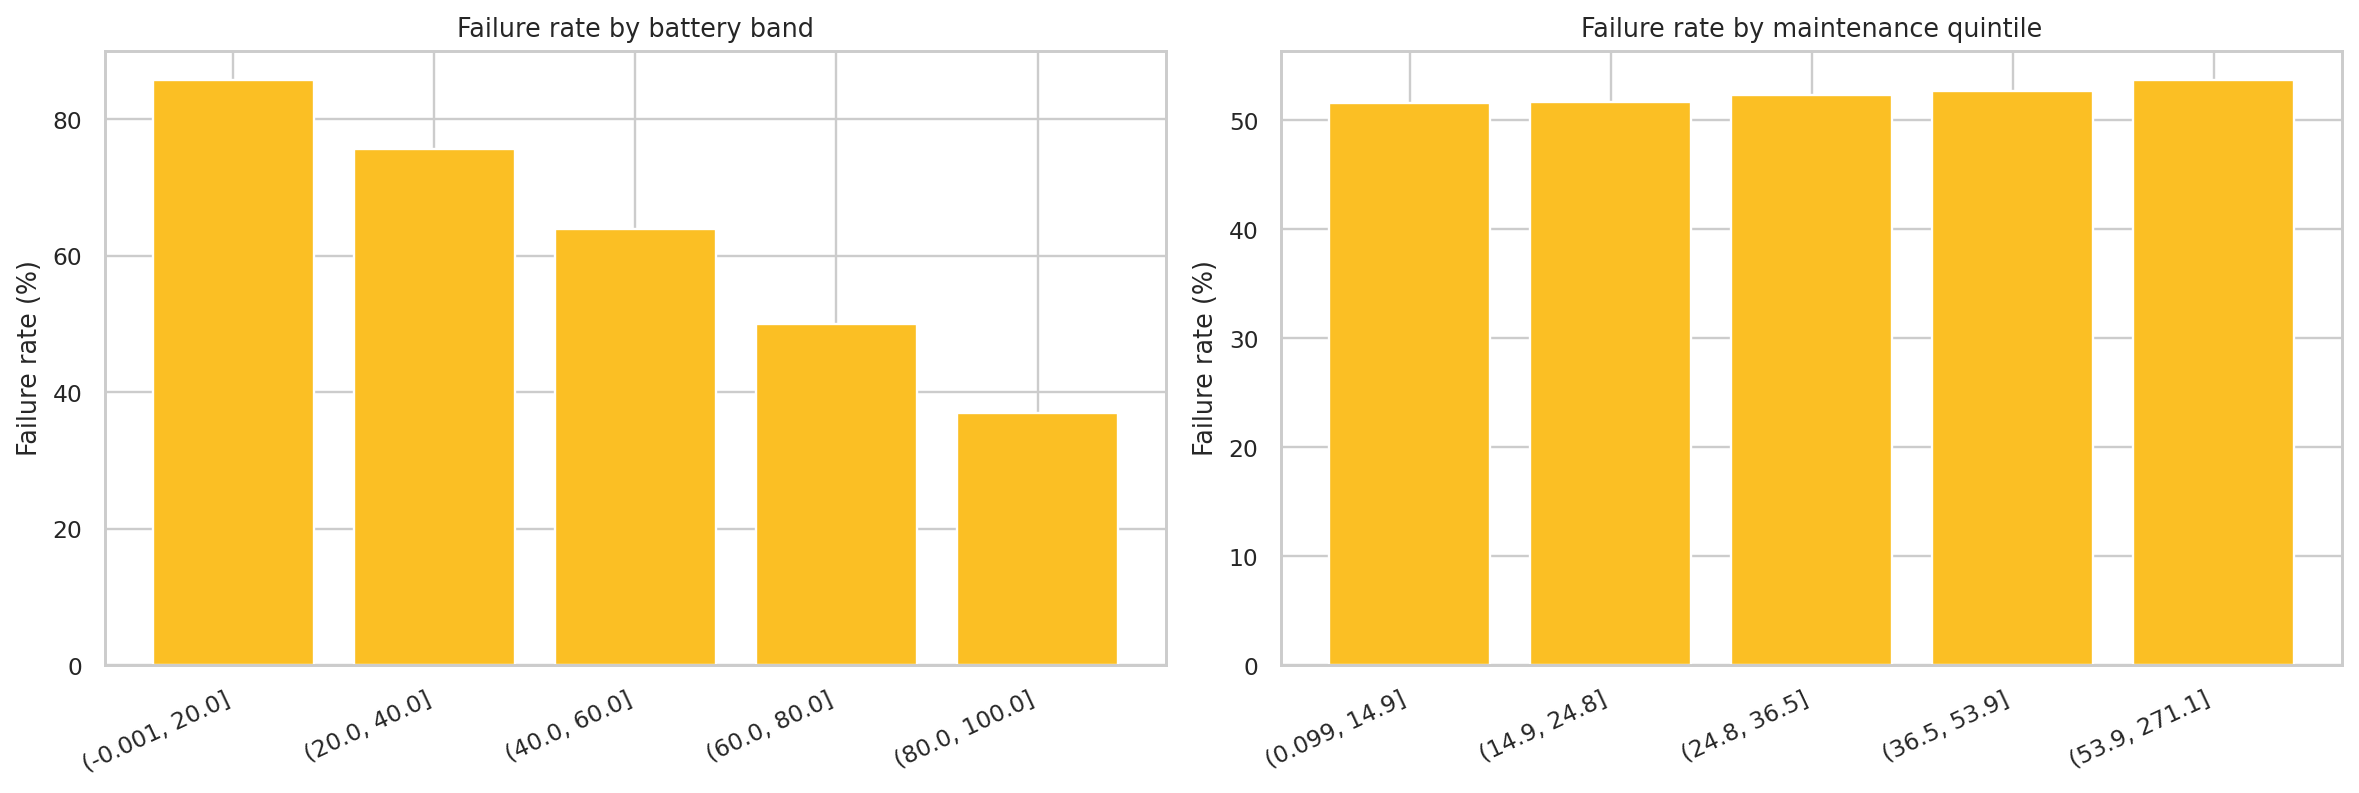

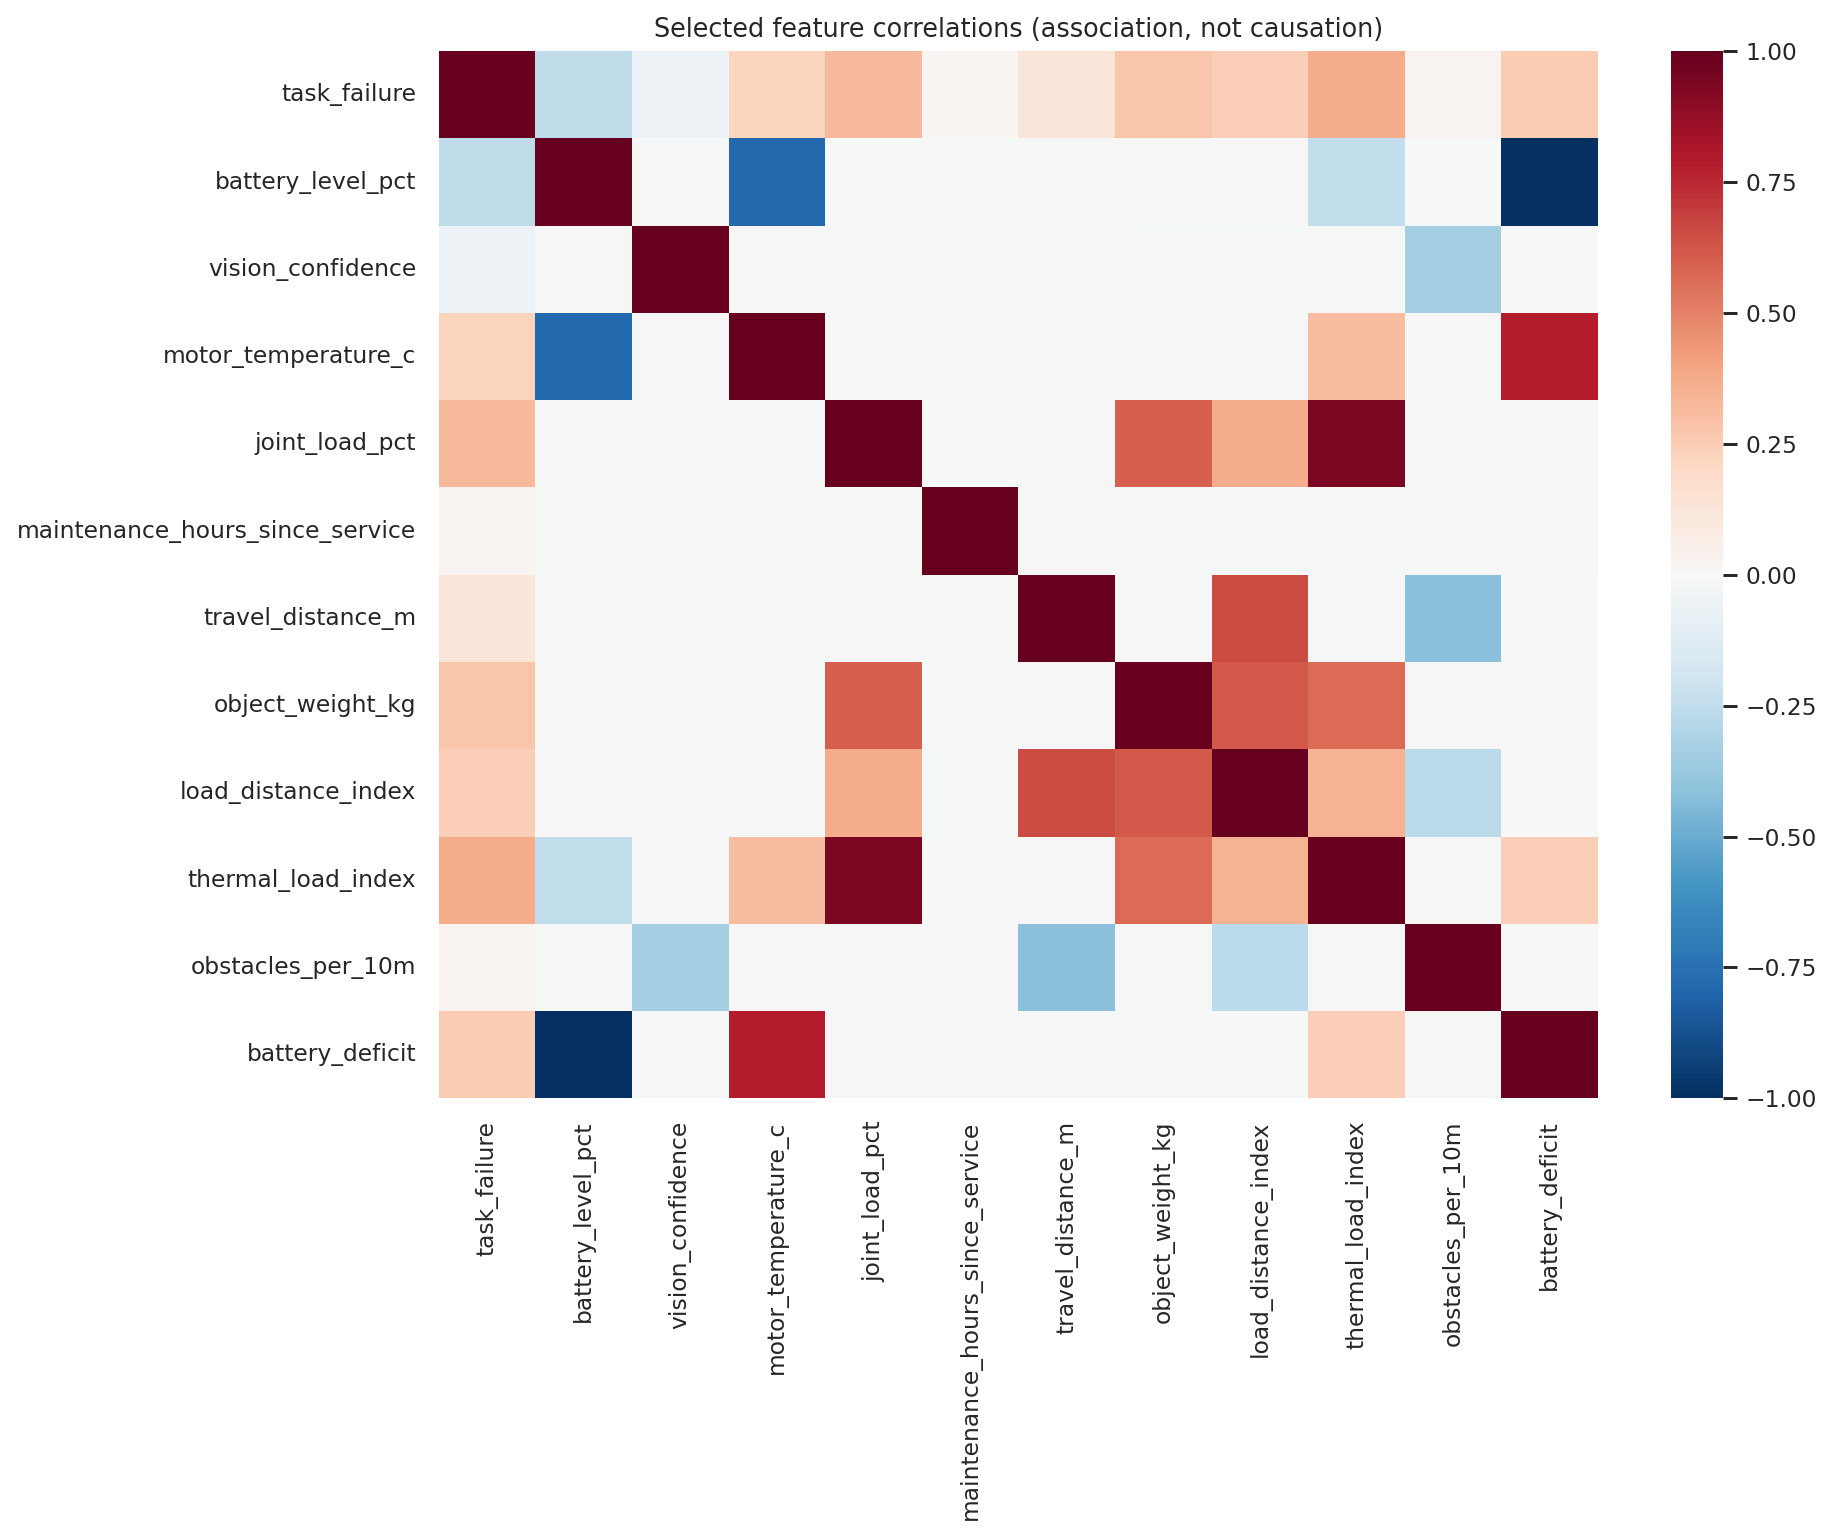

In [4]:
eda_summary = generate_eda(raw, clean)
print(eda_summary)
for name in [
    "01_missingness_before_cleaning.png", "02_target_distribution.png",
    "03_failure_rates_by_category.png", "04_numeric_distributions_by_outcome.png",
    "05_failure_rates_battery_and_maintenance.png", "06_correlation_heatmap.png"
]:
    display(Image(filename=str(FIGURE_DIR / name), width=900))

In [5]:
X, y = prepare_model_data(clean)
print("Model matrix:", X.shape)
print("Failure rate:", round(y.mean(), 4))
assert not {"task_success", "failure_probability_simulated", "completion_time_sec", "operator_intervention", "task_id"}.intersection(X.columns)
display(X.head())

Model matrix: (199950, 31)
Failure rate: 0.5239


,shift,warehouse_zone,task_type,object_weight_kg,object_size_liters,travel_distance_m,obstacles_count,human_nearby,aisle_width_m,floor_friction,lighting_lux,temperature_c,humidity_pct,battery_level_pct,motor_temperature_c,joint_load_pct,grasp_difficulty_1_to_5,vision_confidence,localization_error_cm,network_latency_ms,previous_task_failures,maintenance_hours_since_service,payload_balance_offset_cm,path_planning_complexity_1_to_10,load_distance_index,thermal_load_index,obstacles_per_10m,battery_deficit,maintenance_failure_interaction,low_battery_flag,low_vision_flag
0,afternoon,storage,transport,4.72,11.40,2.60,1.0,0.0,1.43,0.823,255.6,25.9,37.9,83.4,37.6,26.0,2.0,0.893,2.29,95.7,0.0,73.6,2.50,1.0,12.2720,9.7760,2.777778,16.6,73.6,0.0,0.0
1,afternoon,storage,tote_sorting,0.49,8.34,2.26,0.0,0.0,1.56,0.410,305.3,20.7,47.1,81.9,33.5,39.9,3.0,0.989,1.73,58.7,0.0,59.1,3.74,1.0,1.1074,13.3665,0.000000,18.1,59.1,0.0,0.0
2,night,shipping,transport,5.76,8.02,1.26,2.0,1.0,1.19,0.671,161.5,26.4,53.8,60.7,42.2,34.3,2.0,0.978,5.25,33.9,0.0,34.8,0.01,3.0,7.2576,14.4746,8.849558,39.3,34.8,0.0,0.0
3,afternoon,packing,shelf_retrieval,4.47,5.74,1.39,2.0,0.0,2.26,0.723,290.5,27.3,67.6,66.4,33.6,47.0,1.0,0.850,4.07,31.6,0.0,54.4,3.25,2.0,6.2133,15.7920,8.368201,33.6,54.4,0.0,0.0
4,morning,packing,transport,4.86,16.66,8.92,0.0,1.0,1.57,0.817,206.4,NaN,42.8,65.4,45.8,31.1,2.0,1.000,3.75,46.0,0.0,76.4,2.13,2.0,43.3512,14.2438,0.000000,34.6,76.4,0.0,0.0


## 5–6. Model development, tuning, and evaluation

Three candidates are compared: a prior-probability baseline, logistic regression, and random forest. The split is 70% training, 15% validation, and 15% untouched testing, stratified by the target. Hyperparameters are tuned with three-fold cross-validation on a stratified training-only sample; selected configurations are refit on all training data.

The primary threshold minimizes illustrative validation error cost (AED 500 per missed failure and AED 40 per unnecessary review). A balanced F1 threshold and the standard 0.5 threshold are also retained. Costs are scenario assumptions, not observed financial data. Final model configuration is refit on training plus validation and evaluated once on the untouched test set.

In [6]:
results = train_final_model(X, y)
display(results["comparison"])
print("Selected model:", results["metadata"]["selected_model"])
print("Cost-based threshold:", results["metadata"]["decision_threshold"])
print("Balanced F1 threshold:", results["metadata"]["balanced_f1_threshold"])
display(pd.DataFrame([
    {"operating_point": "standard_0.5", **results["metadata"]["test_metrics_default_threshold"]},
    {"operating_point": "balanced_f1", **results["metadata"]["test_metrics_balanced_threshold"]},
    {"operating_point": "high_recall_cost", **results["metadata"]["test_metrics_selected_threshold"]},
]))

,model,tuning_seconds,default_threshold_accuracy,default_threshold_recall,default_threshold_f1,validation_threshold,validation_accuracy,validation_precision,validation_recall,validation_f1,validation_roc_auc,validation_pr_auc,validation_tn,validation_fp,validation_fn,validation_tp,validation_false_positive_cost_aed,validation_false_negative_cost_aed,validation_total_error_cost_aed
2,random_forest,79.42,0.697653,0.710367,0.711137,0.11,0.527441,0.525773,0.999682,0.689114,0.767446,0.781948,111.0,14168.0,5.0,15708.0,566720.0,2500.0,569220.0
1,logistic_regression,5.40,0.701554,0.714440,0.714964,0.08,0.530408,0.527359,0.999173,0.690353,0.773917,0.790140,208.0,14071.0,13.0,15700.0,562840.0,6500.0,569340.0
0,dummy_prior,1.22,0.523906,1.000000,0.687583,0.05,0.523906,0.523906,1.000000,0.687583,0.500000,0.523906,0.0,14279.0,0.0,15713.0,571160.0,0.0,571160.0


Selected model: random_forest
Cost-based threshold: 0.11
Balanced F1 threshold: 0.35


,operating_point,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp,false_positive_cost_aed,false_negative_cost_aed,total_error_cost_aed
0,standard_0.5,0.50,0.699330,0.713529,0.711895,0.712711,0.770419,0.785915,9789,4491,4527,11186,179640,2263500,2443140
1,balanced_f1,0.35,0.662221,0.624509,0.890918,0.734297,0.770419,0.785915,5863,8417,1714,13999,336680,857000,1193680
2,high_recall_cost,0.11,0.526523,0.525278,0.999809,0.688718,0.770419,0.785915,82,14198,3,15710,567920,1500,569420


/usr/local/lib/python3.12/site-packages/sklearn/utils/_plotting.py:175: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


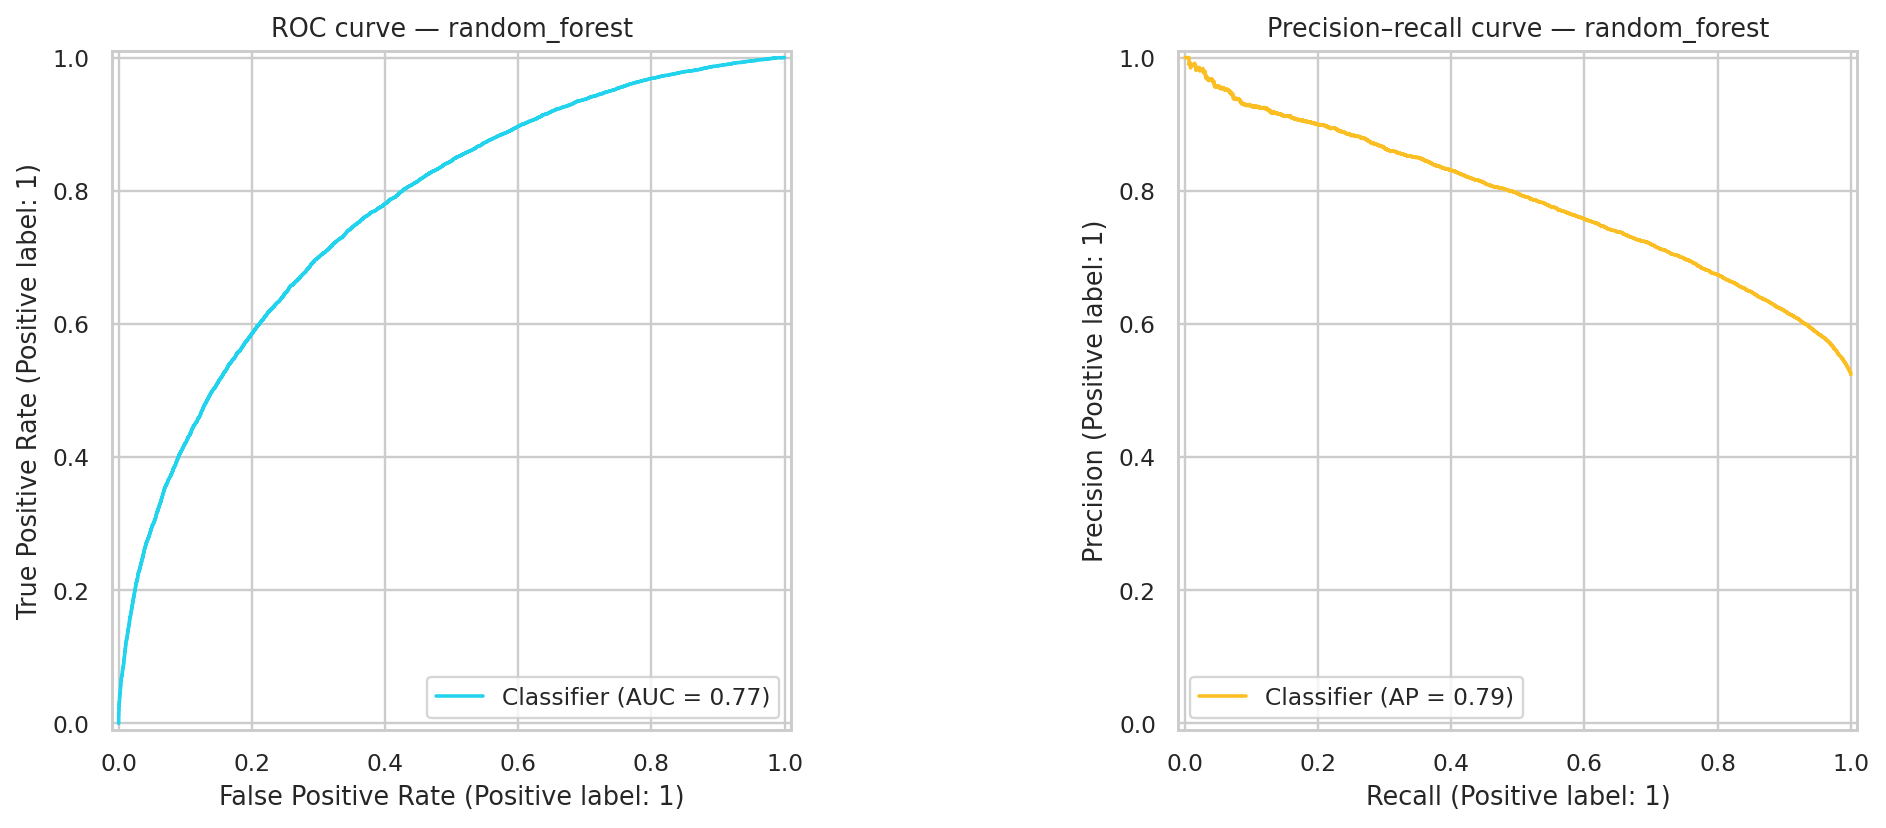

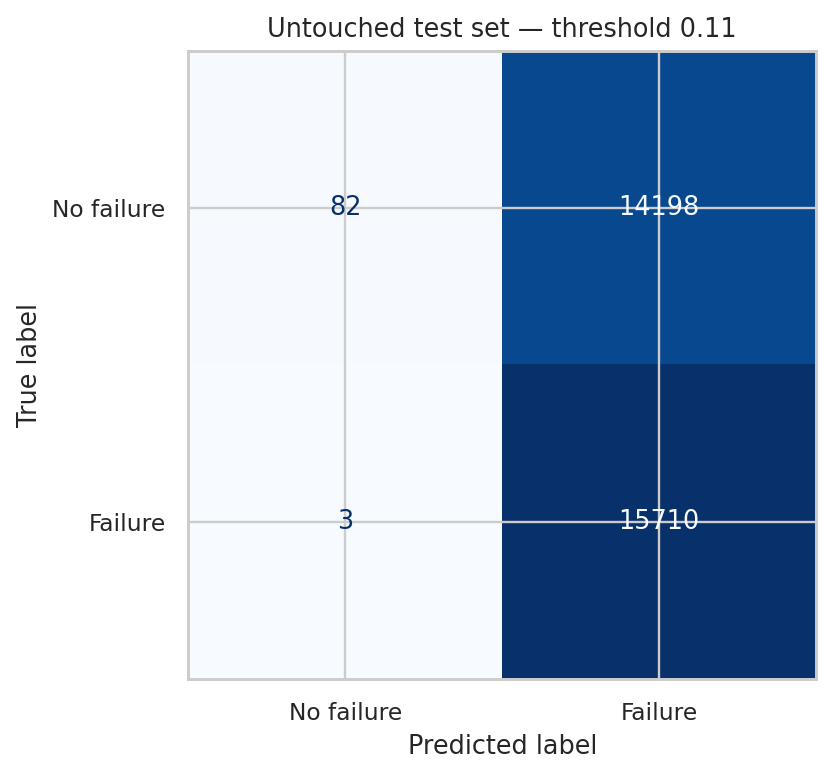

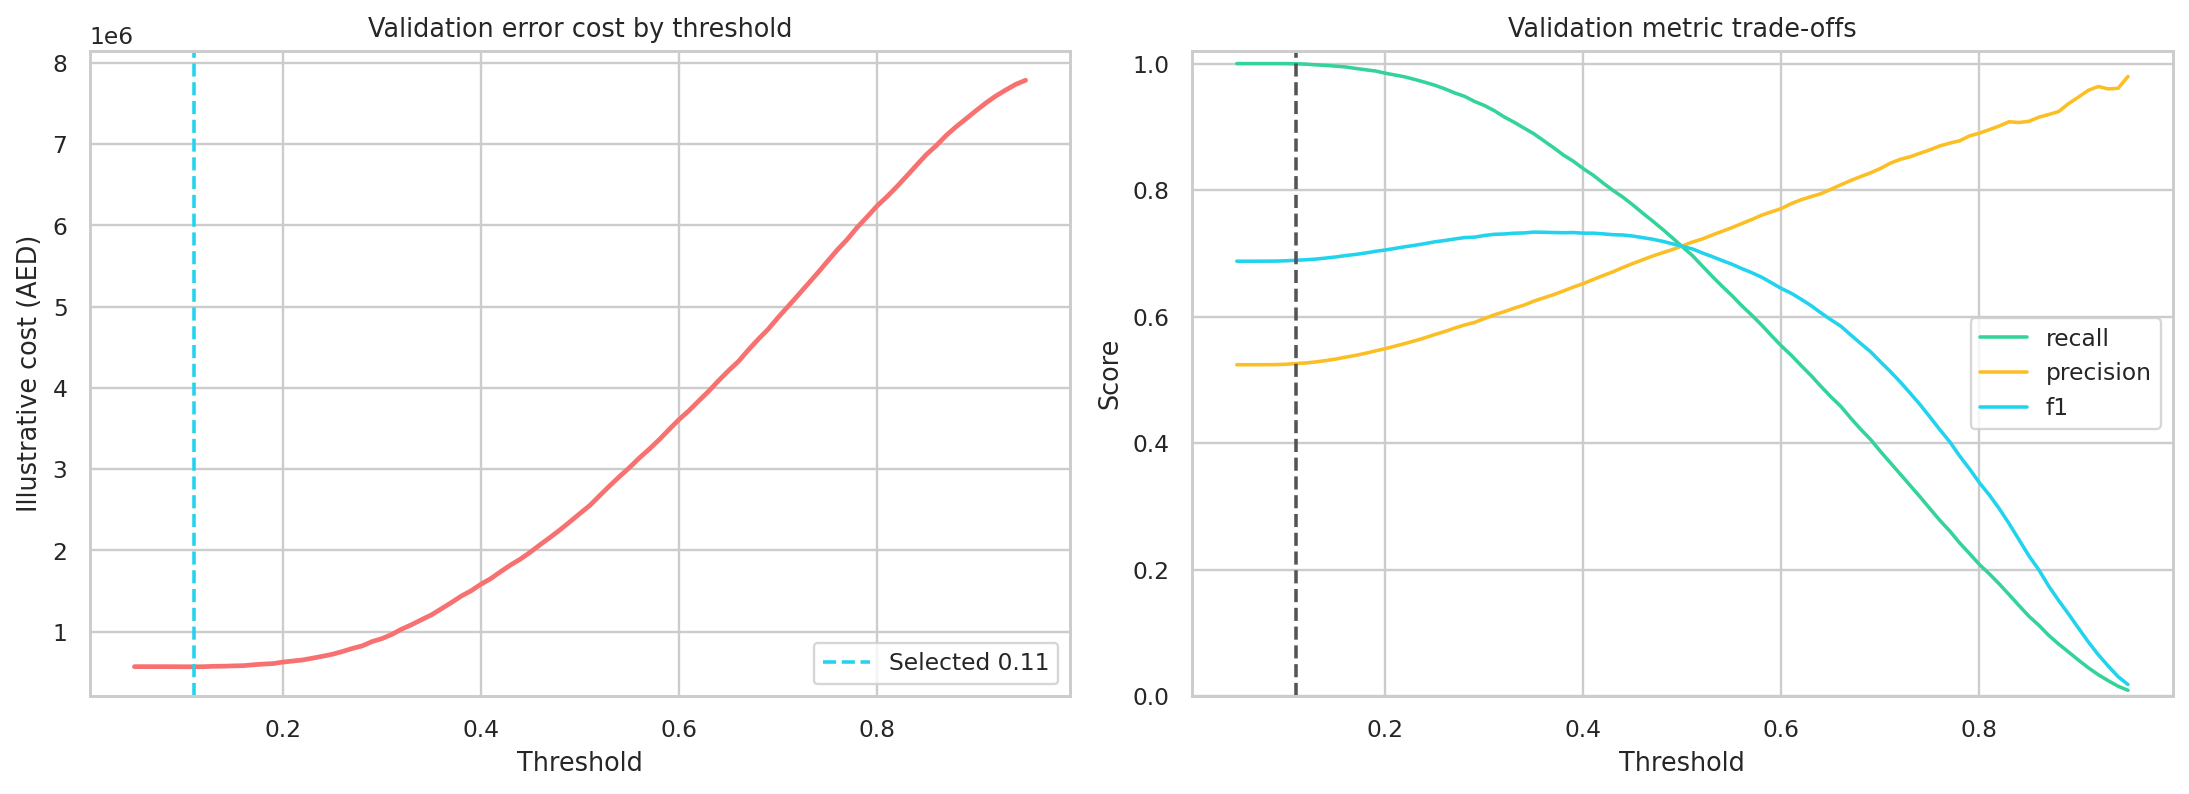

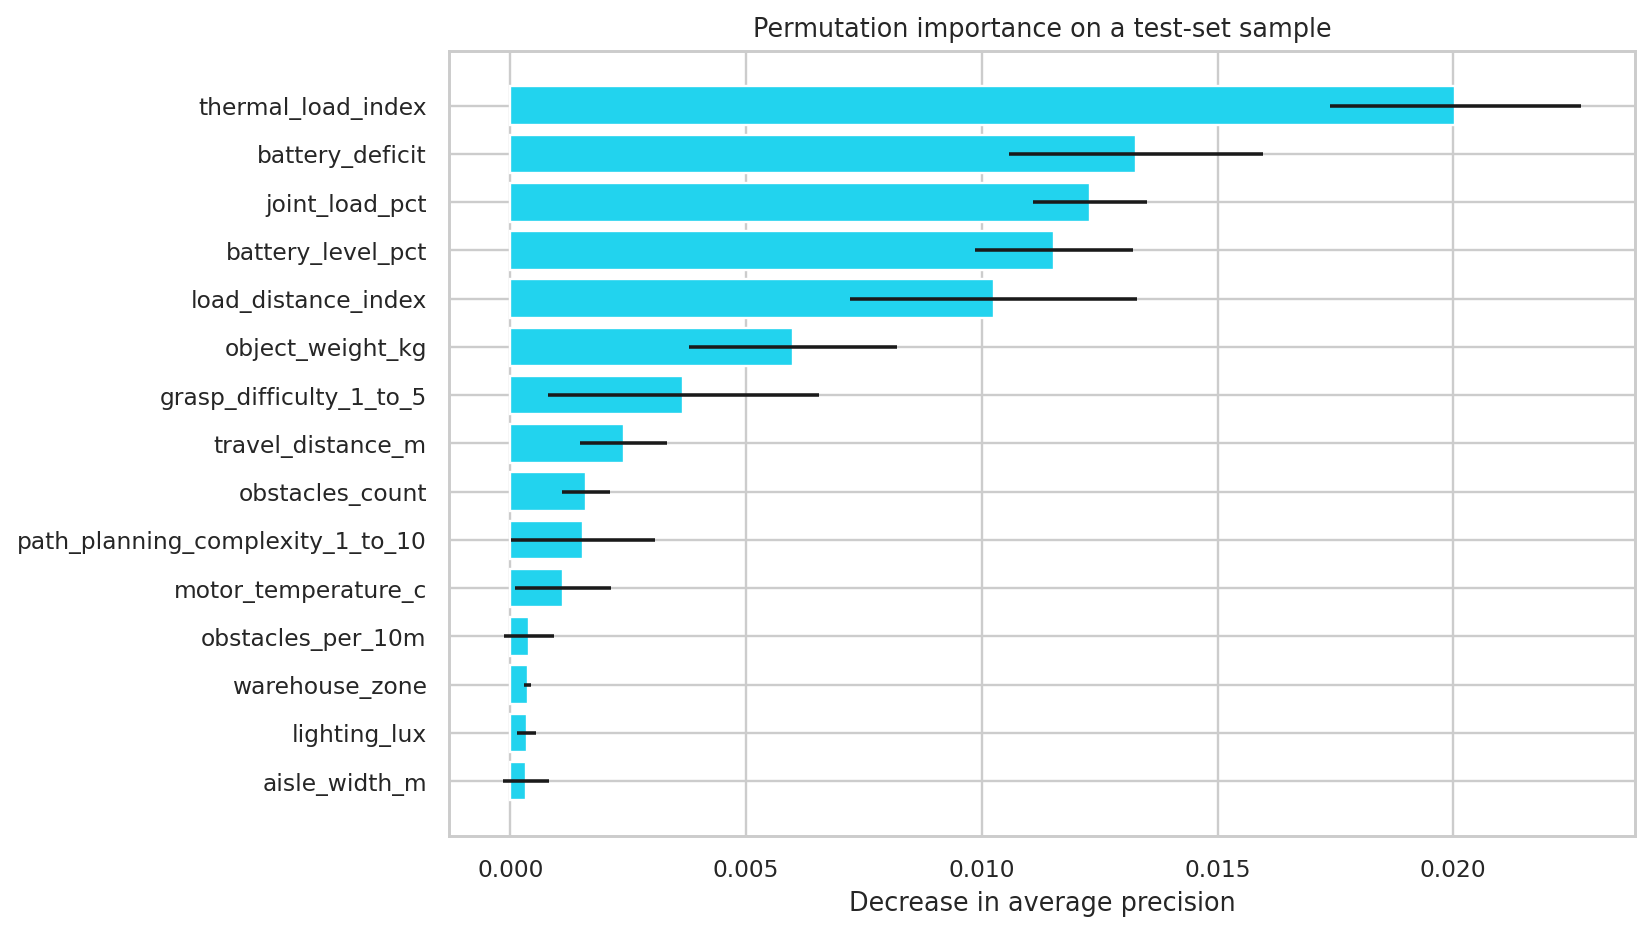

,feature,importance_mean,importance_std
25,thermal_load_index,0.020043,0.002666
27,battery_deficit,0.013263,0.002693
15,joint_load_pct,0.012291,0.001205
13,battery_level_pct,0.011537,0.001671
24,load_distance_index,0.010250,0.003044
3,object_weight_kg,0.006001,0.002210
16,grasp_difficulty_1_to_5,0.003669,0.002869
5,travel_distance_m,0.002403,0.000924
6,obstacles_count,0.001596,0.000509
23,path_planning_complexity_1_to_10,0.001537,0.001524


In [7]:
generate_evaluation_figures(results)
for name in [
    "07_test_roc_and_pr_curves.png", "08_test_confusion_matrix.png",
    "09_threshold_cost_and_metrics.png", "10_permutation_importance.png"
]:
    display(Image(filename=str(FIGURE_DIR / name), width=900))
display(results["importance"].head(15))

## 7. Deployment handoff

The saved pipeline contains median/mode imputation, scaling where required, one-hot encoding, and the selected classifier. The Streamlit app recreates engineered features from raw pre-task inputs and calls this pipeline directly. Users can choose balanced, standard, or high-recall operating points and can score a batch CSV.

In [8]:
example = X.iloc[[0]].copy()
probability = float(results["model"].predict_proba(example)[0, 1])
print(f"Example failure probability: {probability:.3f}")
print("Balanced prediction:", int(probability >= results["metadata"]["balanced_f1_threshold"]))
print("High-recall prediction:", int(probability >= results["metadata"]["decision_threshold"]))

run_summary = {
    "cleaning": {k:v for k,v in cleaning_summary.items() if k != "invalid_by_column"},
    "eda": eda_summary,
    "model_rows": len(X), "model_features": X.shape[1],
    "selected_model": results["metadata"]["selected_model"],
    "decision_threshold": results["metadata"]["decision_threshold"],
    "balanced_f1_threshold": results["metadata"]["balanced_f1_threshold"],
    "test_metrics_high_recall": results["metadata"]["test_metrics_selected_threshold"],
    "test_metrics_balanced": results["metadata"]["test_metrics_balanced_threshold"],
}
(ROOT / "outputs" / "run_summary.json").write_text(json.dumps(run_summary, indent=2))
print("Artifacts saved. Notebook completed top to bottom.")

Example failure probability: 0.282
Balanced prediction: 0
High-recall prediction: 1
Artifacts saved. Notebook completed top to bottom.


### Technical limitations to consider in the student's own reflection

- The data are synthetic; performance may not transfer to physical robots or a real warehouse.
- The supplied file has no external source licence or original clean-data generator.
- Several fields are excluded to reduce target leakage and post-task information leakage.
- The cost-based operating point has very high recall but low precision; its advantage over a flag-all baseline is small under the illustrative costs.
- Thresholds and cost assumptions require validation with operations stakeholders before real use.
- Public GitHub/Streamlit links, team roles, commit evidence, and personal contribution statements must be completed by the students.